# Restructured and cleaned up version of the basic PCI realization

This notebook attempts to reproduce the key products of the restructured-filter-studies notebook in more cleaned up form as of early 2026.


## 0. Necessary installations

Installation of the LISA Simulation suite is required, just like in the workshop:

    #These may be outdated
    pip install numpy scipy sympy h5py matplotlib xarray h5py scikit-learn
    pip install git+https://gitlab.in2p3.fr/lisa-simulation/constants.git@latest
    pip install git+https://gitlab.in2p3.fr/lisa-simulation/instrument.git@latest
    pip install git+https://gitlab.in2p3.fr/lisa-simulation/gw-response.git@latest
    pip install pytdi
    pip install backgrounds

In [1]:
import jax
jax.config.update("jax_enable_x64", True)  #HACK: Some things are coming up zeros with jax, maybe this helps

import importlib
import os
from datetime import datetime

import json
import h5py
import numpy as np
import scipy
import matplotlib.pyplot as plt

from pytdi import Data

from pcipy.data import TimeData
from pcipy.pci_filter import PCIFilter
from pcipy.filter import PiecewiseFilter as PiecewiseFilter
from pcipy.local_pci_filter import LocalPCIFilter
import pcipy.sensitivity as sensitivity

import pyfftw
from pyfftw.interfaces.numpy_fft import rfft

In [2]:
#1. Read in data sets
SKIP_HOURS = 4

RANGE_IN_HOURS = 24*14

DATADIR = "/Users/jbaker/Projects/PCI/late-2025-work/pcipy/data/"
WORKDIR = DATADIR+"/simulations/"

MEASPATH = 'measurements_4Hz.h5'
TDIPATH = 'tdi2_4Hz.h5'
ORBPATH = 'keplerian'

LOCKING='N6-12'
#LOCKING='six'

#JITTER='jitter_'
JITTER=''

substring = [ORBPATH + '_' +
             s for s in ['locking_'+LOCKING+'_laser_tm_oms_'+JITTER, 'all_sky_gw_', 'gw_']]
# substring = ['locking_six_laser_tm_oms', 'all_sky_gw', '2_gw']
sims = ["noise", "all_sky", "point_source"]
datasets = dict(zip(sims, substring))

matchfile = {}
dtpath = {}

for n, d in zip(substring, datasets):
    timestamp = []
    print('searching for:',n)
    matchfile[n] = [f for f in os.listdir(WORKDIR) if n in f]
    for m in matchfile[n]:
        # pick latest date
        timestamp.append(datetime.strptime(m[:11], "%Y-%m-%d_"))
        print(n, timestamp)
        dtpath[d] = max(timestamp).strftime("%Y-%m-%d_")
print(dtpath)

orbits = WORKDIR + ORBPATH + "-orbits.h5"
noise_file_base = dtpath['noise'] + datasets['noise']
gw_file_base = dtpath['all_sky'] + datasets['all_sky']
#gw_file_base = dtpath['point_source'] + datasets['point_source']

searching for: keplerian_locking_N6-12_laser_tm_oms_
keplerian_locking_N6-12_laser_tm_oms_ [datetime.datetime(2026, 7, 9, 0, 0)]
keplerian_locking_N6-12_laser_tm_oms_ [datetime.datetime(2026, 7, 9, 0, 0), datetime.datetime(2026, 7, 9, 0, 0)]
searching for: keplerian_all_sky_gw_
keplerian_all_sky_gw_ [datetime.datetime(2025, 12, 2, 0, 0)]
keplerian_all_sky_gw_ [datetime.datetime(2025, 12, 2, 0, 0), datetime.datetime(2025, 12, 1, 0, 0)]
keplerian_all_sky_gw_ [datetime.datetime(2025, 12, 2, 0, 0), datetime.datetime(2025, 12, 1, 0, 0), datetime.datetime(2025, 12, 2, 0, 0)]
searching for: keplerian_gw_
keplerian_gw_ [datetime.datetime(2025, 12, 2, 0, 0)]
keplerian_gw_ [datetime.datetime(2025, 12, 2, 0, 0), datetime.datetime(2025, 12, 2, 0, 0)]
{'noise': '2026-07-09_', 'all_sky': '2025-12-02_', 'point_source': '2025-12-02_'}


In [3]:
#2. Generate Basic single-link noise data

noise_sim_path = WORKDIR + noise_file_base + MEASPATH

print('reading simulation from:',noise_sim_path)

# get the central frequency
with h5py.File(noise_sim_path, 'r') as sim:
    attributes = json.loads(sim.attrs['metadata_json'])
    central_freq = attributes['central_freq']
    fs = attributes['fs']

data_noise = Data.from_instrument(noise_sim_path)

in_chans = ["sci"]
#in_chans = ["sci", "ref", "tmi"]
# in_chans=["isi","rfi","tmi","isi_sb","rfi_sb"]

in_chansGW = ["sci"]

def make_names(in_chans):
    """

    Parameters
    ----------
    in_chans : TYPE
        DESCRIPTION.

    Returns
    -------
    names : TYPE
        DESCRIPTION.

    """
    mosas_order = ['12', '23', '31', '13', '21', '32']
    names = []
    for chan in in_chans:
        for link in mosas_order:
            names.append(f'{chan}_{link}')
    return names


SKIP = int(SKIP_HOURS * 3600 * fs)
print(SKIP)

# setup instrumental channels
y_names = make_names(in_chans)
# divide by central_freq because simulation channels are in beat-rate units
y_list = [data_noise.measurements[name]/central_freq for name in y_names]
# create a TimeData object
y_n = TimeData(np.array(y_list, dtype=np.float64)[:, SKIP:],
               dt=1/fs,
               t0=SKIP/fs,
               names=y_names)


# In[4]: 3.2 Matching GW simulations results for the empirical sensitivity calculation

# we need these only for the sensitivity calculation

gw_path = WORKDIR+gw_file_base+MEASPATH

data_gw = Data.from_gws(gw_path,orbits)

y_namesGW = make_names(in_chansGW)
# #note: the GW mesaurement data are already fractional frequency so we don't divide by central_freq
y_list = [data_gw.measurements[name] for name in y_namesGW]
print(y_list)
np.array(y_list, dtype=np.float64)
y_gw = TimeData(np.array(y_list, dtype=np.float64)[:,SKIP:],dt=1/fs,t0=SKIP/fs,names=y_namesGW)


You are using a GW file in a version that might not be fully supported


reading simulation from: /Users/jbaker/Projects/PCI/late-2025-work/pcipy/data//simulations/2026-07-09_keplerian_locking_N6-12_laser_tm_oms_measurements_4Hz.h5
57600


You are using an orbit file in a version that might not be fully supported


[array([-1.41632032, -0.69311517,  0.77876657, ...,  0.39048086,
       -1.09957272,  1.19657138], shape=(1036800,)), array([ 1.59617394, -0.01736913,  0.17493602, ...,  0.22864093,
       -0.83424273, -0.50197507], shape=(1036800,)), array([-0.06541711, -0.32268751, -1.89618023, ..., -0.6444277 ,
       -1.50888836,  0.47132676], shape=(1036800,)), array([-0.0071528 ,  0.28215591, -0.91863577, ...,  0.66760965,
        0.41628684,  0.07508159], shape=(1036800,)), array([-0.00471052,  0.8045424 ,  0.27495304, ..., -0.79777095,
       -0.31748646, -0.21881929], shape=(1036800,)), array([-0.68682979,  0.241871  , -0.78731567, ..., -0.40345769,
        1.54841282,  0.00750714], shape=(1036800,))]


In [4]:
#hack to adapt to older notation below (FIXME)
y_full=y_n.data.T
skip=300
print(y_full.shape)

(979200, 6)


## Sensitivity

So far, the rest of this notebook is no longer the further restructured version of the previous notebook, but really a development effort for the sensitivity calculation.  TBD move this to a new notebook.

### So far we do not understand what is happening with the sensitivity calculation. 

Both the empirical and the backgrounds-based calculations are yielding sensitivity estimates which are far too low.  

There are a few effects that we at least partially understand.

 - When the Welch P/CSD nperseg value is too high (less smoothing) the sensitivity often comes out underestimated.  In our case we see this, sometimes to an extreme degree, but for small nperseg, the sensitivity still saturates at about few e-28 levels.
 - There could be issues with the new backgrounds-based calculation which doesn't rely on a simulation of the GW response.  However, when the Welch estimate issue is controlled, we do see approximate agreement.  Note that the backgrounds-based calculation may be more strongly affected by inaccurate CSD computation because the GW-response part is computed analytically (no Welch estimation).
 - There is another similar notebook/script (pci-single-noise) which at least shows approximate agreement of the PCI sensitivity.  Understanding the difference there may be key. Here are some differences:
   - The other script does not use the new generic filter interface in LocalPCIFilter
   - The other script does not use the same sensitivity calculation code, but a closely related version, coded directly in the notebook
   - The other script does PCI the old way (on the eta channels)
   - We also note that the PCI variance found in this notebook have similar shape to those in the other notebook compressed into the first 2/3s of the components, but the last 3rd are about 15-18 orders of magnitude smaller 

In [5]:
# Function to help with applying the empirical sensitivity calculation in the same way to either native or LinearFilter versions of PCI
def apply_pci_filter(pcifilt,timedata):
    #unpack time data, apply the pcifilter natively, repack timedata
    outdata = pcifilt.apply_for_channels(timedata.data)
    return TimeData(outdata,dt=timedata.dt,t0=timedata.t0+pcifilt.nhalf*timedata.dt)
def change_names(timedata,inbase,outbase):
    assert(timedata.match_names(make_names([inbase]),verbose=True))
    return TimeData(timedata.data,dt=timedata.dt,t0=timedata.t0,names=make_names([outbase]))

#### Plan
  - Redo the LocalPCIFilter realization here mainly independent of the more wide-ranging code above
    - Also made the data size/range more closely match that in the other notebook
    - $\color{red}{\text{Done, no surprises or big effects}}$
    - Also played with number of channels.
    - $\color{red}{\text{For one channel (with nperseg=2000,hours=12) empirical and backgrounds estimates are quite similar} \textit{ except } \text{ for a factor of about 1.3 (empircal is higher) }}$
  - Try here with sci channels only
    - $\color{red}{\text{ Done, results look similar}}$
  - Try here PCI built the other way but compute the sensitivity
    - $\color{red}{\text{Implemented. We can reproduce the differences both ways now.}}$
  - Try PCIFilter, but with the sci channels
    - $\color{red}{\text{Here we also see the smae extra-small variances now with PCIFilter}}$
  - Try LocalPCIFilter, but with the eta channels
    - $\color{red}{\text{}}$
  - TBD
 

In [6]:
# TDI2 fractional delay Lagrange interpolating polynomials are of order 31=1+15*2
# Overall TDI delays are up to 8x single link delay = 8.34 s * 4 Hz * 8 = about 267 sample
# Add 15 on each end: 267 + 2*15 = 297   
# TDI2 overall stencil is then about 297 samples
# aPCI overall stencil width is 1 + nhalf*2
nhalf = 45
pci_regard_hours=12
ns = int(pci_regard_hours * 3600 * fs)
Tscale=10

ncompts=6
orderk=1

In [7]:
# redo LocalPCIFilter instantiation for more controlled testing:

in_chans = ["sci"]
more_in_chans = ["sci", "ref", "tmi"]
#in_chans=["isi","rfi","tmi","isi_sb","rfi_sb"]

pcifilt = LocalPCIFilter(data_noise, in_chans=in_chans, skip_secs=SKIP/fs, 
                                      pci_regard_hours=pci_regard_hours, 
                                      nhalf=nhalf, pci_order=orderk, n_compts=ncompts, 
                                      sort_by_rms=False,Tscale=Tscale, testPCI=True)   


iskip= 57600
prelim ieval,i0,pci_ns,data_ns: 86445 0 172800 1036800
final i0,pci_ns,data_ns: 0 172800 1036800
check t0: 0.0 14400.0
pci(): [[-3.18695723e+00 -1.11603614e+01 -3.80501394e+01 ... -7.77767970e+01
   1.68008637e+02  8.54351070e+01]
 [ 4.72575990e+01  5.21252719e+00 -1.15125634e+02 ...  2.45201777e+01
  -1.00659442e+01 -5.47711382e+01]
 [ 6.16612511e+01  8.90224370e+01 -8.08749773e+01 ...  4.86602343e+01
  -5.10607167e+01  5.97446643e+01]
 [-5.86379577e-16  5.26500300e-14  4.07146395e-15 ...  9.76970235e-14
   4.69235318e-14  1.27284803e-14]
 [ 1.00845683e-13  7.06162364e-14 -1.44665161e-14 ... -2.16790662e-14
   5.37222662e-14 -4.88779095e-14]
 [ 1.90034448e-14 -2.93055112e-14 -4.53472573e-14 ... -1.21157160e-13
  -1.31476051e-13  3.19093645e-14]] 4.0 45 1 6 None None False False False 10 None None
(172800, 1092)
variance check rms: 181602.91506004744
shapes of chans, cov, components: (6, 172800) (6, 6) (6, 1092)
[  1673.19690765   3339.6059345    3928.31625799   4867.52021

In [8]:
welch_kwargs = {"fs": fs,
          "window": 'blackman',
          "nperseg": 2000,
          "detrend": 'constant',
          "return_onesided": True,
          "scaling": 'density'}
welch_kwargs['detrend']=None

ioff=0
ytest_n=y_n.get_range(ns*ioff,ns*(1+ioff)+2*nhalf)
ytest_gw=y_gw.get_range(ns*ioff,ns*(1+ioff)+2*nhalf)

nside = 5
sens_list = []
#sens_list += [['std-pci0,emp,chans', 
#     sensitivity.estimate_sensitivity_empirically(pcifilt,ytest_n,ytest_gw, strainPSD=2, gw_input_names=y_namesGW, joint=False,welch_kwargs=welch_kwargs)
#    ]]
#sens_list += [['std-pci0,bgs,chans', 
#     sensitivity.estimate_sensitivity(pcifilt,ytest_n,orbits=orbits,joint=False,welch_kwargs=welch_kwargs,nsideGWB=nside)
#    ]]
sens_list += [['std-pci'+str(orderk)+',emp,joint', 
     sensitivity.estimate_sensitivity_empirically(pcifilt,ytest_n,ytest_gw, strainPSD=2, gw_input_names=make_names(['sci']), joint=True,welch_kwargs=welch_kwargs)
    ]]
sens_list += [['std-pci'+str(orderk)+',bgs,joint', 
     sensitivity.estimate_sensitivity(pcifilt,ytest_n,orbits=orbits,joint=True,welch_kwargs=welch_kwargs,nsideGWB=nside)
    ]]
sens_list += [['std-pci'+str(orderk)+',native-emp,joint', 
     
     sensitivity.estimate_sensitivity_empirically(None,apply_pci_filter(pcifilt.pci_TEST,ytest_n),apply_pci_filter(pcifilt.pci_TEST,ytest_gw),strainPSD=2,joint=True,welch_kwargs=welch_kwargs)
    ]]
#sens_list += [['std-pci0,nb-bgs,joint', 
#     estimate_sensitivity(pcifilt,ytest_n,orbits=orbits,joint=True,welch_kwargs=welch_kwargs,nsideGWB=nside)
#    ]]
#sens_list += [['tdi', 
#     sensitivity.estimate_sensitivity(pcifilt,ytest_n,orbits=orbits,joint=True,welch_kwargs=welch_kwargs,use_TDI_design_matrix=True,analytic=True,nsideGWB=nside)
#    ]]

/Users/jbaker/miniforge3/envs/pcienv/lib/python3.14/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/jbaker/miniforge3/envs/pcienv/lib/python3.14/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


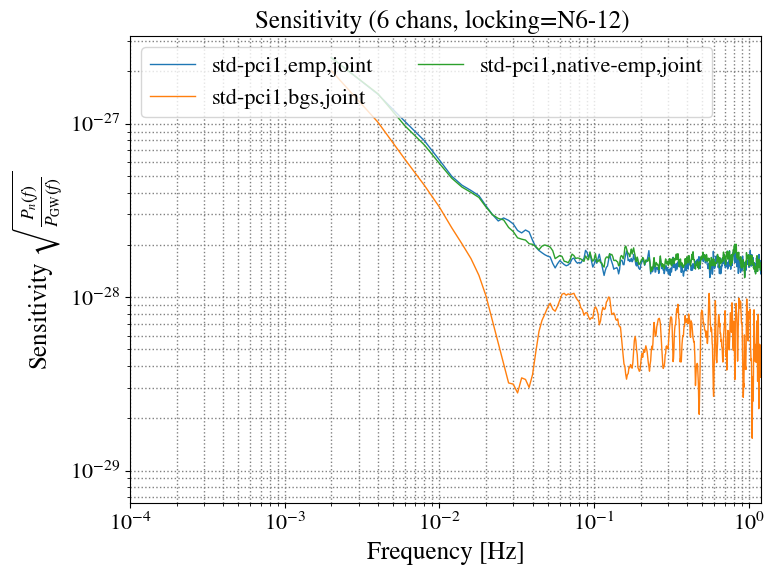

In [9]:
from pcipy import plotting 
plotting.plotconfig(lbsize=18, lgsize=16)
_, axes = plt.subplots(1, 1, figsize=(8, 6))

for j in range(len(sens_list)):
    #print(j)
    axes.loglog(sens_list[j][1][0], np.sqrt(sens_list[j][1][1]), 
                linewidth=1, label=sens_list[j][0], rasterized=True)
axes.legend(loc='upper left', ncol=2)
axes.set_xlabel("Frequency [Hz]")
axes.set_ylabel(r"Sensitivity $\sqrt{\frac{P_{n}(f)}{P_{\mathrm{GW}}(f)}}$")
axes.set_xlim([1e-4, 1.2])
#axes.set_ylim([3e-19, 1e-13])
axes.grid(linewidth=1, which='both', color='gray', linestyle='dotted')
axes.set_title("Sensitivity ("+str(ncompts)+" chans, locking="+LOCKING+") ")
plt.show()

In [10]:
#Now try to reproduce the PCI calc from the pci-single-noise
from pytdi.intervar import ETA_SET
def build_data_vector(data_noise, skip=300, dtype=np.float64):
    central_freq = 281600000000000.0
    # Conventions 1, 2, 3, 1p, 2p, 3p
    # delays_order = ['23', '31', '12', '32', '13', '21']
    mosas_order = ['12', '23', '31', '13', '21', '32']
    # Form intermediary variables for full data
    ETA_data_set = {key: ETA_SET[key].build(**data_noise.args) for key in ETA_SET.keys()}
    eta_noise_set = {key: ETA_data_set[key](data_noise.measurements) for key in ETA_data_set.keys()}
    # Form the measurement vector for moving arms containing all noises
    y = np.array([eta_noise_set[f'eta_{mosa}'] / central_freq for mosa in mosas_order], dtype=dtype).T
    y_full = y[skip:, :]
    del y

    return y_full

etas_full = build_data_vector(data_noise, skip=skip, dtype=np.float64)
# setup instrumental channels
eta_names = make_names(["eta"])
# create a TimeData object
etas_n = TimeData(np.array(etas_full.T, dtype=np.float64)[:, SKIP:],
               dt=1/fs,
               t0=SKIP/fs,
               names=eta_names)



In [11]:
#This is a hack to make LocalPCIFIlter work on non pytdi data
class meas():
    def __init__(self,data,names):
        self.sa = np.array(data,dtype=[(name,'f8') for name in names])
    def __getitem__(self, i):
        return self.sa[i]
    def values(self):
        return self.sa
class meas_data():
    def __init__(self,fs,data,names):
        self.fs = fs
        if len(names)!=len(data):
            print('yikes', data.shape)
        self.measurements = {name:data[i] for i,name in enumerate(names)}

#md=meas_data(fs,y_n.data,y_names)
print(eta_names)
md=meas_data(fs,etas_full.T,eta_names)
mdm=md.measurements
display(mdm)



['eta_12', 'eta_23', 'eta_31', 'eta_13', 'eta_21', 'eta_32']


{'eta_12': array([ 2.08343094e-13,  3.23007973e-13,  7.13455117e-14, ...,
        -8.67216267e-14, -8.66186614e-14,  3.62016158e-14],
       shape=(1036500,)),
 'eta_23': array([ 1.08354672e-13,  6.73558671e-14,  2.95819278e-13, ...,
        -1.26356499e-13,  2.87115591e-13,  2.39669455e-13],
       shape=(1036500,)),
 'eta_31': array([-2.96399841e-13, -3.40491361e-13, -5.71089056e-14, ...,
        -1.55627369e-13, -1.50927010e-13, -2.64351683e-13],
       shape=(1036500,)),
 'eta_13': array([ 1.23792039e-14,  5.17479706e-14,  2.65832362e-13, ...,
        -3.66192701e-13, -1.53571038e-14,  5.62951468e-14],
       shape=(1036500,)),
 'eta_21': array([ 5.96949174e-20, -1.77200730e-19,  3.74818997e-20, ...,
        -2.48656770e-20,  1.59170143e-19,  1.66685166e-20],
       shape=(1036500,)),
 'eta_32': array([-5.54745400e-20, -8.78366038e-20,  1.80172778e-19, ...,
         1.85636172e-19,  7.16889771e-20,  3.00724120e-20],
       shape=(1036500,))}

In [12]:
from pcipy.pci_filter import PCIFilter
pci_rs0 = PCIFilter(etas_full[SKIP:SKIP+ns+2*nhalf, :].T,
                    fs=fs,
                    nhalf=nhalf,
                    order=orderk,
                    maxcompts=ncompts,
                    Tscale=Tscale,
                    sort_by_rms=True)
pci_rs0_sci = PCIFilter(y_full[SKIP:SKIP+ns+2*nhalf, :6].T,
                    fs=fs,
                    nhalf=nhalf,
                    order=orderk,
                    maxcompts=ncompts,
                    Tscale=Tscale,
                    sort_by_rms=True)
               
pcifilt_eta = LocalPCIFilter(meas_data(fs,etas_full.T,eta_names), in_chans=["eta"], skip_secs=SKIP/fs, 
                             pci_regard_hours=pci_regard_hours, 
                             nhalf=nhalf, pci_order=orderk, n_compts=ncompts, 
                             sort_by_rms=False,Tscale=Tscale, testPCI=True)

pci_k = PCIFilter(etas_full[SKIP:SKIP+ns+2*nhalf, :].T,
                    fs=fs,
                    nhalf=nhalf,
                    order=orderk,
                    maxcompts=ncompts,
                    Tscale=Tscale,
                    sort_by_rms=False)


pci(): [[-2.17868372e-14  2.66268547e-14 -1.08725067e-13 ... -1.05509983e-13
   1.52374219e-13  2.44132073e-13]
 [-1.13432573e-13  3.48333940e-15 -4.27497425e-13 ...  1.40843835e-14
   6.58155184e-14  8.33576193e-14]
 [-5.54338756e-16 -2.08930909e-13  4.73829866e-13 ... -1.47577976e-13
  -2.31475651e-13 -2.13755192e-13]
 [-1.90522539e-13 -1.03559458e-13 -1.07638900e-13 ... -3.18664432e-13
   6.12444201e-14  3.62090000e-14]
 [ 8.88348698e-20 -1.13017704e-19  1.50243183e-19 ... -2.93574944e-20
  -3.72340884e-20  1.10903777e-19]
 [-5.22454524e-20  6.88255256e-20 -4.01627659e-21 ...  1.10341741e-19
   3.52278775e-20 -6.76959398e-20]] 4.0 45 1 6 None None False False True 10 None None
(172800, 1092)
variance check rms: 2.07065116434919e-08
shapes of chans, cov, components: (6, 172800) (6, 6) (6, 1092)
[1.00000001 1.         1.00000001 0.99999999 1.         1.        ]
channel covariance diagonality test on 6 components: 3.2866221004609334e-09
component diagonality test on 6 components: 2.07

In [13]:
dA=pci_k.__dict__
#dA=pcifilt_more.pci_TEST.__dict__
dB=pcifilt_eta.pci_TEST.__dict__
import pandas as pd
names=list(set(dA.keys()).union(set(dB.keys())))
df=pd.DataFrame(data=None, index=names, columns=None, dtype=None, copy=None)
df['A']=[dA.get(name, "NOT_FOUND") for name in names]
df['B']=[dB.get(name, "NOT_FOUND") for name in names]
df.loc['explained_rms']
df.loc['explained_rms_rev']=[x[::-1] for x in df.loc['explained_rms']]
display(df)

,A,B
ref_t0,0,0
nc,6,6
window,"[False, False, False, False, False, False, Fal...","[False, False, False, False, False, False, Fal..."
components,"[[-0.0001413312767646053, -1.3629792233928458e...","[[-0.0001413312767646053, -1.3629792233928458e..."
nsdata,172890,172890
stencil_compts,"[[[-0.0001413312767646053, -1.3629792233928458...","[[[-0.0001413312767646053, -1.3629792233928458..."
explained_variance,"[1.5486249020292952e-24, 1.547326731510715e-24...","[1.5486249020292952e-24, 1.547326731510715e-24..."
nhalf,45,45
scaled_t0,5.0,5.0
explained_rms,"[1.2444341871495963e-12, 1.243912286780901e-12...","[1.2444341871495963e-12, 1.243912286780901e-12..."


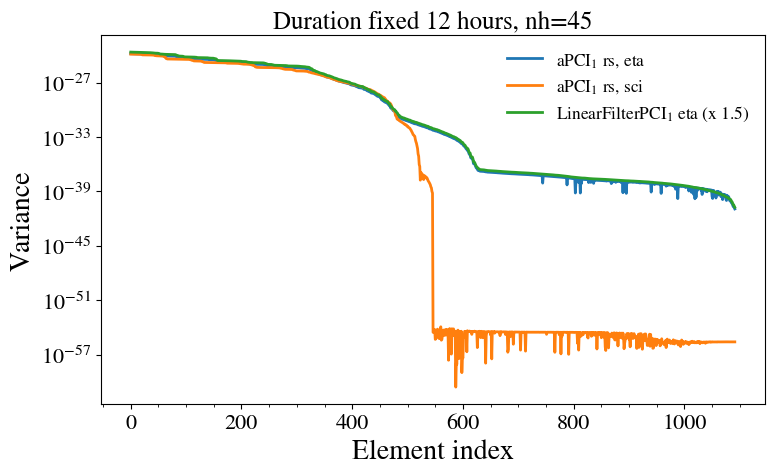

zsh:1: command not found: free


/Users/jbaker/miniforge3/envs/pcienv/lib/python3.14/pty.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


In [14]:
fig1, ax1 = plt.subplots(nrows=1,figsize=(8,5))

q=orderk
ax1.plot(pci_rs0.explained_variance, 
        label=r'aPCI$_'+str(q)+'$ rs, eta',
        linewidth=2,
        rasterized=False) 
ax1.plot(pci_rs0_sci.explained_variance, 
        label=r'aPCI$_'+str(q)+'$ rs, sci',
        linewidth=2,
        rasterized=False) 
ax1.plot(pcifilt_eta.pci_TEST.explained_variance*1.5, 
        label=r'LinearFilterPCI$_'+str(q)+'$ eta (x 1.5)',
        linewidth=2,
        rasterized=False) 
ax1.set_xscale('linear')
ax1.set_yscale('log')
ax1.set_xlabel(r"Element index", fontsize=20)
ax1.set_ylabel("Variance", fontsize=20)
# ax1.set_ylim([1e-42, 1e-25])
ax1.minorticks_on()
plt.legend(loc='upper right', frameon=False, fontsize="small")
plt.title("Duration fixed "+str(int(ns/fs/3600))+ " hours, nh=" + str(nhalf))
plt.show()
!free
#for i in range(3):
#    print(pca_list[i].explained_variance-pca_list_zm[i].explained_variance)

In [15]:
etatest_n=etas_n.get_range(0,ns+2*nhalf)

sens_list = []
#sens_list += [['std-pci0,emp,chans', 
#     sensitivity.estimate_sensitivity_empirically(pcifilt,ytest_n,ytest_gw, strainPSD=2, gw_input_names=y_namesGW, joint=False,welch_kwargs=welch_kwargs)
#    ]]
#sens_list += [['std-pci0,bgs,chans', 
#     sensitivity.estimate_sensitivity(pcifilt,ytest_n,orbits=orbits,joint=False,welch_kwargs=welch_kwargs,nsideGWB=nside)
#    ]]
sens_list += [['lf-pci'+str(orderk)+',nat-emp,joint',     
     sensitivity.estimate_sensitivity_empirically(None,apply_pci_filter(pcifilt.pci_TEST,ytest_n),apply_pci_filter(pcifilt.pci_TEST,ytest_gw),strainPSD=2,joint=True,welch_kwargs=welch_kwargs)
    ]]
sens_list += [['lf-pci'+str(orderk)+',bgs,joint', 
     sensitivity.estimate_sensitivity(pcifilt,ytest_n,orbits=orbits,joint=True,welch_kwargs=welch_kwargs,nsideGWB=nside)
    ]]
sens_list += [['pci_rs'+str(orderk)+',nat-emp,joint',     
     sensitivity.estimate_sensitivity_empirically(None,apply_pci_filter(pci_rs0,etatest_n),apply_pci_filter(pci_rs0,ytest_gw),strainPSD=2,joint=True,welch_kwargs=welch_kwargs)
    ]]
sens_list += [['pci_rs'+str(orderk)+'_sci,nat-emp,joint',     
     sensitivity.estimate_sensitivity_empirically(None,apply_pci_filter(pci_rs0_sci,ytest_n),apply_pci_filter(pci_rs0_sci,ytest_gw),strainPSD=2,joint=True,welch_kwargs=welch_kwargs)
    ]]
sens_list += [['lf-pci'+str(orderk)+'_eta,bgs,joint', 
     sensitivity.estimate_sensitivity(pcifilt_eta,etatest_n,orbits=orbits,joint=True,welch_kwargs=welch_kwargs,nsideGWB=nside,gw_ch_base_name='eta')
    ]]
sens_list += [['lf-pci'+str(orderk)+'_eta,nat-emp,joint', 
     sensitivity.estimate_sensitivity_empirically(None,apply_pci_filter(pcifilt_eta.pci_TEST,etatest_n),apply_pci_filter(pcifilt_eta.pci_TEST,ytest_gw),strainPSD=2,joint=True,welch_kwargs=welch_kwargs)
    ]]
sens_list += [['lf-pci'+str(orderk)+'_eta,emp,joint', 
     sensitivity.estimate_sensitivity_empirically(pcifilt_eta,etatest_n,change_names(ytest_gw,'sci','eta'),strainPSD=2,joint=True,welch_kwargs=welch_kwargs)
    ]]
#sens_list += [['pci_'+str(orderk)+',nat-emp,joint',     
#     sensitivity.estimate_sensitivity_empirically(None,apply_pci_filter(pci_k,etatest_n),apply_pci_filter(pci_k,ytest_gw),strainPSD=2,joint=True,welch_kwargs=welch_kwargs)
#    ]]
sens_list += [['tdi', 
     sensitivity.estimate_sensitivity(pcifilt,ytest_n,orbits=orbits,joint=True,welch_kwargs=welch_kwargs,use_TDI_design_matrix=True,analytic=True,nsideGWB=nside)
    ]]

/Users/jbaker/miniforge3/envs/pcienv/lib/python3.14/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/jbaker/miniforge3/envs/pcienv/lib/python3.14/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


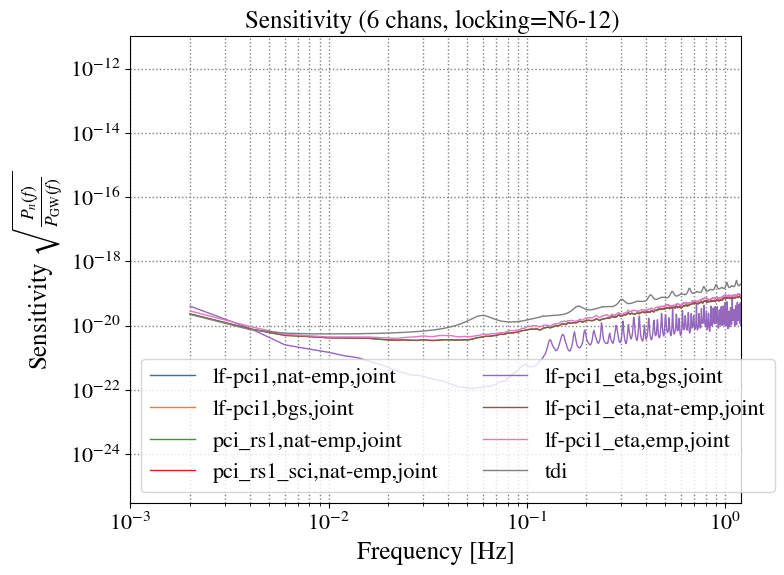

In [16]:
from pcipy import plotting 
plotting.plotconfig(lbsize=18, lgsize=16)
_, axes = plt.subplots(1, 1, figsize=(8, 6))

for j in range(len(sens_list)):
    #print(j)
    axes.loglog(sens_list[j][1][0], np.sqrt(sens_list[j][1][1]), 
                linewidth=1, label=sens_list[j][0], rasterized=True)
axes.legend(loc='lower left', ncol=2)
axes.set_xlabel("Frequency [Hz]")
axes.set_ylabel(r"Sensitivity $\sqrt{\frac{P_{n}(f)}{P_{\mathrm{GW}}(f)}}$")
axes.set_xlim([1e-3, 1.2])
axes.set_ylim([3e-26, 1e-11])
axes.grid(linewidth=1, which='both', color='gray', linestyle='dotted')
axes.set_title("Sensitivity ("+str(ncompts)+" chans, locking="+LOCKING+") ")
plt.show()

In [17]:
# try more channels:

                   
pcifilt_more = LocalPCIFilter(data_noise, in_chans=more_in_chans, skip_secs=SKIP/fs, 
                                      pci_regard_hours=pci_regard_hours, 
                                      nhalf=nhalf, pci_order=orderk, n_compts=ncompts, 
                                      sort_by_rms=False,Tscale=Tscale, testPCI=True)   

ymore_n = TimeData(np.array([data_noise.measurements[name]/central_freq for name in make_names(more_in_chans)], dtype=np.float64)[:, SKIP:],
               dt=1/fs,
               t0=SKIP/fs,
               names=make_names(more_in_chans))
                   
ymoretest_n=ymore_n.get_range(ns*ioff,ns*(1+ioff)+2*nhalf)

iskip= 57600
prelim ieval,i0,pci_ns,data_ns: 86445 0 172800 1036800
final i0,pci_ns,data_ns: 0 172800 1036800
check t0: 0.0 14400.0
pci(): [[-3.18695723e+00 -1.11603614e+01 -3.80501394e+01 ... -7.77767970e+01
   1.68008637e+02  8.54351070e+01]
 [ 4.72575990e+01  5.21252719e+00 -1.15125634e+02 ...  2.45201777e+01
  -1.00659442e+01 -5.47711382e+01]
 [ 6.16612511e+01  8.90224370e+01 -8.08749773e+01 ...  4.86602343e+01
  -5.10607167e+01  5.97446643e+01]
 ...
 [-5.79616036e+00 -8.13062380e+01  1.14218405e+02 ...  8.25404030e+01
  -9.55073606e+01 -7.18370209e+01]
 [-1.72198522e-05 -1.16143502e-05 -4.44442223e-06 ...  2.86837683e-05
  -1.36581235e-05 -1.01865042e-05]
 [ 1.40203482e-05 -2.16556581e-05  2.14850591e-05 ... -1.94321967e-05
  -6.09630037e-05  1.73172210e-05]] 4.0 45 1 6 None None False False False 10 None None
(172800, 3276)
variance check rms: 309294.57991025434
shapes of chans, cov, components: (6, 172800) (6, 6) (6, 3276)
[ 12681.47605483  14684.57025113  14404.13506102 130749.

In [18]:
sens_list = []


#sens_list += [['lf-pci'+str(orderk)+'_sci+rfi+tmi,bgs,joint', 
#     sensitivity.estimate_sensitivity(pcifilt_more,ymoretest_n,orbits=orbits,joint=True,welch_kwargs=welch_kwargs,nsideGWB=nside)
#    ]]
#sens_list += [['lf-pci'+str(orderk)+'_sci+rfi+tmi,emp,joint',     
#     sensitivity.estimate_sensitivity_empirically(pcifilt_more,ymoretest_n,ytest_gw,strainPSD=2,gw_input_names=y_namesGW,joint=True,welch_kwargs=welch_kwargs)
#    ]]
sens_list += [['PCI'+str(orderk)+',sci+rfi+tmi',     
     sensitivity.estimate_sensitivity_empirically(None,apply_pci_filter(pcifilt_more.pci_TEST,ymoretest_n),pcifilt_more.restrict(input_names=make_names(['sci'])).apply_filter(ytest_gw),joint=True,welch_kwargs=welch_kwargs)
    ]]
#sens_list += [['lf-pci'+str(orderk)+'_eta,bgs,joint', 
#     sensitivity.estimate_sensitivity(pcifilt_eta,etatest_n,orbits=orbits,joint=True,welch_kwargs=welch_kwargs,nsideGWB=nside,gw_ch_base_name='eta')
#    ]]
sens_list += [['PCI'+str(orderk)+',eta',     
     sensitivity.estimate_sensitivity_empirically(None,apply_pci_filter(pcifilt_eta.pci_TEST,etatest_n),apply_pci_filter(pcifilt_eta.pci_TEST,ytest_gw),strainPSD=2,joint=True,welch_kwargs=welch_kwargs)
    ]]
sens_list += [['TDI(theory)', 
     sensitivity.estimate_sensitivity(pcifilt,ytest_n,orbits=orbits,joint=True,welch_kwargs=welch_kwargs,use_TDI_design_matrix=True,analytic=True,nsideGWB=nside)
    ]]

/Users/jbaker/miniforge3/envs/pcienv/lib/python3.14/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/jbaker/miniforge3/envs/pcienv/lib/python3.14/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


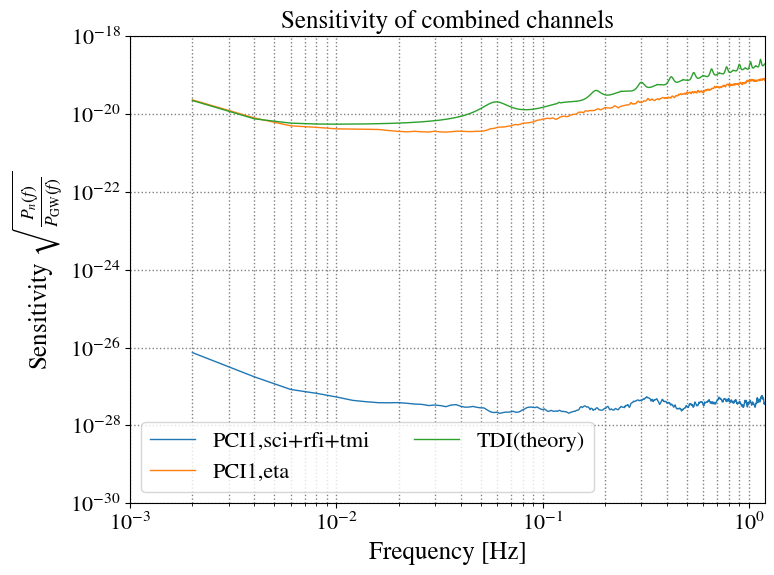

In [19]:
from pcipy import plotting 
plotting.plotconfig(lbsize=18, lgsize=16)
_, axes = plt.subplots(1, 1, figsize=(8, 6))

for j in range(len(sens_list)):
    #print(j)
    axes.loglog(sens_list[j][1][0], np.sqrt(sens_list[j][1][1]), 
                linewidth=1, label=sens_list[j][0], rasterized=True)
axes.legend(loc='lower left', ncol=2)
axes.set_xlabel("Frequency [Hz]")
axes.set_ylabel(r"Sensitivity $\sqrt{\frac{P_{n}(f)}{P_{\mathrm{GW}}(f)}}$")
axes.set_xlim([1e-3, 1.2])
axes.set_ylim([1e-30, 1e-18])
axes.grid(linewidth=1, which='both', color='gray', linestyle='dotted')
axes.set_title("Sensitivity of combined channels")
plt.show()

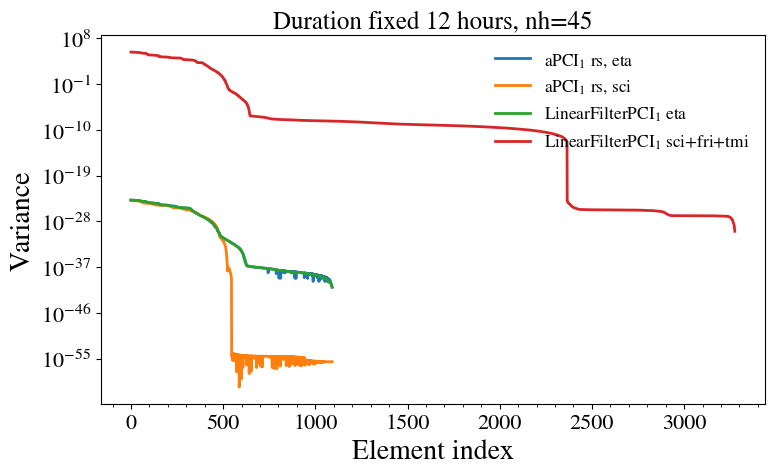

zsh:1: command not found: free


/Users/jbaker/miniforge3/envs/pcienv/lib/python3.14/pty.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


In [20]:
fig1, ax1 = plt.subplots(nrows=1,figsize=(8,5))

ax1.plot(pci_rs0.explained_variance, 
        label=r'aPCI$_'+str(q)+'$ rs, eta',
        linewidth=2,
        rasterized=False) 
ax1.plot(pci_rs0_sci.explained_variance, 
        label=r'aPCI$_'+str(q)+'$ rs, sci',
        linewidth=2,
        rasterized=False) 
ax1.plot(pcifilt_eta.pci_TEST.explained_variance, 
        label=r'LinearFilterPCI$_'+str(q)+'$ eta',
        linewidth=2,
        rasterized=False) 
ax1.plot(pcifilt_more.pci_TEST.explained_variance, 
        label=r'LinearFilterPCI$_'+str(q)+'$ sci+fri+tmi',
        linewidth=2,
        rasterized=False) 
ax1.set_xscale('linear')
ax1.set_yscale('log')
ax1.set_xlabel(r"Element index", fontsize=20)
ax1.set_ylabel("Variance", fontsize=20)
# ax1.set_ylim([1e-42, 1e-25])
ax1.minorticks_on()
plt.legend(loc='upper right', frameon=False, fontsize="small")
plt.title("Duration fixed "+str(int(ns/fs/3600))+ " hours, nh=" + str(nhalf))
plt.show()
!free
#for i in range(3):
#    print(pca_list[i].explained_variance-pca_list_zm[i].explained_variance)